In [1]:
# Core libraries used throughout this notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
print("Libraries loaded.")

Libraries loaded.


In [ ]:
missing_percentage = df.isnull().mean() * 100
print(missing_percentage)

In [2]:
# df = pd.read_csv("titanic.csv")
import seaborn as sns
df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
print("Shape (rows, columns):", df.shape)
print("\nColumns:", list(df.columns))

Shape (rows, columns): (891, 15)

Columns: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [4]:
df.info


<bound method DataFrame.info of      survived  pclass     sex   age  sibsp  parch     fare embarked   class  \
0           0       3    male  22.0      1      0   7.2500        S   Third   
1           1       1  female  38.0      1      0  71.2833        C   First   
2           1       3  female  26.0      0      0   7.9250        S   Third   
3           1       1  female  35.0      1      0  53.1000        S   First   
4           0       3    male  35.0      0      0   8.0500        S   Third   
..        ...     ...     ...   ...    ...    ...      ...      ...     ...   
886         0       2    male  27.0      0      0  13.0000        S  Second   
887         1       1  female  19.0      0      0  30.0000        S   First   
888         0       3  female   NaN      1      2  23.4500        S   Third   
889         1       1    male  26.0      0      0  30.0000        C   First   
890         0       3    male  32.0      0      0   7.7500        Q   Third   

       who  adult_m

In [5]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
df.sample(3,random_state=1)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
862,1,1,female,48.0,0,0,25.9292,S,First,woman,False,D,Southampton,yes,True
223,0,3,male,NaN,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
84,1,2,female,17.0,0,0,10.5000,S,Second,woman,False,NaN,Southampton,yes,True


In [12]:
df.sample(3)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
281,0,3,male,28.0,0,0,7.8542,S,Third,man,True,NaN,Southampton,no,True
11,1,1,female,58.0,0,0,26.5500,S,First,woman,False,C,Southampton,yes,True
455,1,3,male,29.0,0,0,7.8958,C,Third,man,True,NaN,Cherbourg,yes,True


In [13]:
df.isnull().head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False


In [14]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [15]:
missing_count=df.isnull().sum()
missing_count[missing_count > 0]

age            177
embarked         2
deck           688
embark_town      2
dtype: int64

In [17]:
missing_percentage=df.isnull().mean()*100
missing_percentage[missing_percentage > 0].round(2)


age            19.87
embarked        0.22
deck           77.22
embark_town     0.22
dtype: float64

In [18]:
missing_summary = pd.DataFrame({
    "Column": missing_count[missing_count > 0].index,
    "Missing Count": missing_count[missing_count > 0].values,
    "Missing Percentage": missing_percentage[missing_percentage > 0].round(2).values
})
missing_summary

,Column,Missing Count,Missing Percentage
0,age,177,19.87
1,embarked,2,0.22
2,deck,688,77.22
3,embark_town,2,0.22


In [19]:
demo_dropped_rows = df.dropna(subset=["embarked"])
print("Rows before:", len(df))
print("Rows after dropping missing Embarked:", len(demo_dropped_rows))

Rows before: 891
Rows after dropping missing Embarked: 889


In [20]:
demo_dropped_cols = df.dropna(axis=1)
print("Columns before:", list(df.columns))
print("Columns after dropna(axis=1):", list(demo_dropped_cols.columns))


Columns before: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']
Columns after dropna(axis=1): ['survived', 'pclass', 'sex', 'sibsp', 'parch', 'fare', 'class', 'who', 'adult_male', 'alive', 'alone']


In [21]:
age_mean = df["age"].mean()
age_filled_mean = df["age"].fillna(age_mean)
print("Mean Age:", round(age_mean, 2))
print("Missing after mean imputation:", age_filled_mean.isnull().sum())


Mean Age: 29.7
Missing after mean imputation: 0


In [22]:
age_median = df["age"].median()
age_filled_median = df["age"].fillna(age_median)
print("Median Age:", age_median)
print("Missing after median imputation:", age_filled_median.isnull().sum())


Median Age: 28.0
Missing after median imputation: 0


In [23]:
embarked_mode = df["embarked"].mode()[0]
embarked_filled = df["embarked"].fillna(embarked_mode)
print("Mode of Embarked:", embarked_mode)
print("Missing after mode imputation:", embarked_filled.isnull().sum())

Mode of Embarked: S
Missing after mode imputation: 0


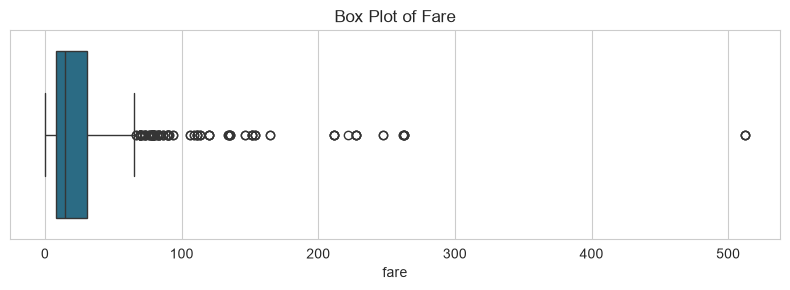

In [24]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["fare"], color="#1C7293")
plt.title("Box Plot of Fare")
plt.tight_layout()
plt.show()

In [25]:
Q1 = df["fare"].quantile(0.25)
Q3 = df["fare"].quantile(0.75)
print("Q1:", Q1)
print("Q3:", Q3)

Q1: 7.9104
Q3: 31.0


In [26]:
IQR = Q3 - Q1
print("IQR:", IQR)


IQR: 23.0896


In [27]:

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print("Lower Bound:", round(lower, 2))
print("Upper Bound:", round(upper, 2))

Lower Bound: -26.72
Upper Bound: 65.63


In [ ]:
outliers = df[
    (df["fare"] < lower) |
    (df["fare"] > upper)
]
print(outliers)
print("Number of Fare outliers:", len(outliers))
outliers[["survived", "pclass", "fare"]].sort_values("fare", ascending=False).head(10)

     survived  pclass     sex   age  sibsp  parch      fare embarked  class  \
1           1       1  female  38.0      1      0   71.2833        C  First   
27          0       1    male  19.0      3      2  263.0000        S  First   
31          1       1  female   NaN      1      0  146.5208        C  First   
34          0       1    male  28.0      1      0   82.1708        C  First   
52          1       1  female  49.0      1      0   76.7292        C  First   
..        ...     ...     ...   ...    ...    ...       ...      ...    ...   
846         0       3    male   NaN      8      2   69.5500        S  Third   
849         1       1  female   NaN      1      0   89.1042        C  First   
856         1       1  female  45.0      1      1  164.8667        S  First   
863         0       3  female   NaN      8      2   69.5500        S  Third   
879         1       1  female  56.0      0      1   83.1583        C  First   

       who  adult_male deck  embark_town alive  alo

,survived,pclass,fare
258,1,1,512.3292
737,1,1,512.3292
679,1,1,512.3292
27,0,1,263.0000
341,1,1,263.0000
438,0,1,263.0000
88,1,1,263.0000
311,1,1,262.3750
742,1,1,262.3750
299,1,1,247.5208


In [ ]:
missing_percentage = df.isnull().mean() * 100
print(missing_percentage)

In [ ]:
df = df.dropna(subset=['Embarked'])

In [ ]:
df['Age_imputed'] = df['Age'].fillna(df['Age'].median())

In [ ]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [ ]:
Q1 = df['Fare'].quantile(0.25)
Q3 = df['Fare'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

In [ ]:
fare_outliers = df[
    (df['Fare'] < lower_bound) |
    (df['Fare'] > upper_bound)
]

print(fare_outliers)

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df[['Age_scaled', 'Fare_scaled']] = scaler.fit_transform(
    df[['Age', 'Fare']]
)

print(df[['Age_scaled', 'Fare_scaled']].min())
print(df[['Age_scaled', 'Fare_scaled']].max())

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df[['Age_standardized', 'Fare_standardized']] = scaler.fit_transform(
    df[['Age', 'Fare']]
)

print(df[['Age_standardized', 'Fare_standardized']].mean())
print(df[['Age_standardized', 'Fare_standardized']].std())

In [ ]:
encoded_df = pd.get_dummies(
    df,
    columns=['Sex', 'Embarked'],
    dtype=int
)

print(encoded_df.head())

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)